# 3. Model A: single-image classifier

Fine-tunes EfficientNet-B2 to classify one signature as genuine or forged, for each of the 5 writer-independent
folds. The decision threshold (on the logit) is picked on the validation writers at the EER point and then applied
unchanged to the test writers. Saves `runs/binary_fold<k>/` (`best.pt`, `history.csv`, `metrics.json`,
`test_scores.npy`).

Regularisation against memorising the 36 training writers: augmentation before the DIP pipeline (affine +
stroke-width jitter), label smoothing, dropout 0.5, weight decay 0.05, low backbone LR, cosine schedule.

Folds that already have results are loaded, not retrained, unless `RETRAIN = True` (≈ 9 min per fold on an RTX 3050).

In [1]:
MODE = "binary"
FOLDS = [0, 1, 2, 3, 4]
EPOCHS = 15
BATCH = 16
LR = 1e-4                # backbone; the head uses 10x
WEIGHT_DECAY = 0.05
SMOOTH = 0.1             # label smoothing
SEED = 42
RETRAIN = False

In [2]:
%run ./common.ipynb

In [3]:
import json
import time

import matplotlib.pyplot as plt


def train_fold(fold):
    name = f"{MODE}_fold{fold}"
    out = os.path.join(RUNS, name)
    os.makedirs(out, exist_ok=True)
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    device = DEVICE

    meta, tr, va, te = writer_split(fold=fold)
    G, y = load_gray(MODE), meta.label.values
    print(f"[{name}] train {len(tr)} / val {len(va)} / test {len(te)} images, "
          f"test writers {sorted(set(meta.writer.values[te].tolist()))}")

    def loader(idx, train):
        return ThreadLoader(SignatureSet(np.asarray(G[idx]), y[idx], train), batch_size=BATCH,
                            shuffle=train, drop_last=train)

    dl_tr, dl_va, dl_te = loader(tr, True), loader(va, False), loader(te, False)

    model = build_model().to(device)
    head = list(model.classifier.parameters())
    head_ids = {id(p) for p in head}
    body = [p for p in model.parameters() if id(p) not in head_ids]
    opt = torch.optim.AdamW([{"params": body, "lr": LR},
                             {"params": head, "lr": LR * 10}], weight_decay=WEIGHT_DECAY)
    sched = warmup_cosine(opt, len(dl_tr), EPOCHS * len(dl_tr))
    scaler = torch.amp.GradScaler(enabled=device.type == "cuda")
    loss_fn = nn.BCEWithLogitsLoss()

    best_auc, hist = -1.0, []
    for ep in range(1, EPOCHS + 1):
        model.train()
        t0, run = time.time(), 0.0
        for xb, yb in dl_tr:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            with torch.autocast(device.type, enabled=device.type == "cuda"):
                loss = loss_fn(model(xb).squeeze(1), yb * (1 - SMOOTH) + SMOOTH / 2)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            run += loss.item() * len(yb)

        s, yv = predict(model, dl_va, device)
        thr, _ = eer_threshold(yv, s)
        m = metrics(yv, s, thr)
        hist.append({"epoch": ep, "train_loss": run / (len(dl_tr) * BATCH), **{f"val_{k}": v for k, v in m.items()}})
        flag = ""
        if m["auc"] > best_auc:
            best_auc, flag = m["auc"], "  *"
            torch.save({"model": model.state_dict(), "thr": thr, "mode": MODE}, os.path.join(out, "best.pt"))
        print(f"ep {ep:2d}  loss {hist[-1]['train_loss']:.4f}  val acc {m['acc']:.3f}  auc {m['auc']:.4f}  "
              f"eer {m['eer']:.3f}  ({time.time() - t0:.0f}s){flag}", flush=True)

    pd.DataFrame(hist).to_csv(os.path.join(out, "history.csv"), index=False)

    ck = torch.load(os.path.join(out, "best.pt"), map_location=device)
    model.load_state_dict(ck["model"])
    s, yt = predict(model, dl_te, device)
    res = {"name": name, "mode": MODE, "fold": fold, "best_val_auc": best_auc,
           "test": metrics(yt, s, ck["thr"]),
           "test_writers": sorted(set(int(w) for w in meta.writer.values[te]))}
    np.save(os.path.join(out, "test_scores.npy"), np.stack([te, yt, s]))   # index, label, logit
    with open(os.path.join(out, "metrics.json"), "w") as f:
        json.dump(res, f, indent=2)
    return res

In [4]:
results = []
for fold in FOLDS:
    path = os.path.join(RUNS, f"{MODE}_fold{fold}", "metrics.json")
    if os.path.exists(path) and not RETRAIN:
        res = json.load(open(path))
        print(f"fold {fold}: loaded existing results")
    else:
        res = train_fold(fold)
    results.append({"fold": fold, **res["test"]})

df = pd.DataFrame(results).set_index("fold")[["auc", "eer", "acc", "far", "frr", "thr"]]
print(df.round(4))
d = df.drop(columns="thr")
print("\nmean +/- std (population std, as in summarize.ipynb):")
print(pd.DataFrame({"mean": d.mean(), "std": d.std(ddof=0)}).T.round(4))

fold 0: loaded existing results
fold 1: loaded existing results
fold 2: loaded existing results
fold 3: loaded existing results
fold 4: loaded existing results
         auc     eer     acc     far     frr     thr
fold                                                
0     0.8074  0.2917  0.6913  0.5227  0.0947  0.7041
1     0.7217  0.3523  0.6705  0.0379  0.6212  1.1016
2     0.7810  0.2803  0.7140  0.2841  0.2879  1.3711
3     0.6783  0.3674  0.5833  0.2348  0.5985  0.7305
4     0.7672  0.3087  0.6818  0.2311  0.4053  1.3672

mean +/- std (population std, as in summarize.ipynb):
         auc     eer     acc     far     frr
mean  0.7511  0.3201  0.6682  0.2621  0.4015
std   0.0458  0.0340  0.0448  0.1552  0.1970


## Validation AUC per epoch

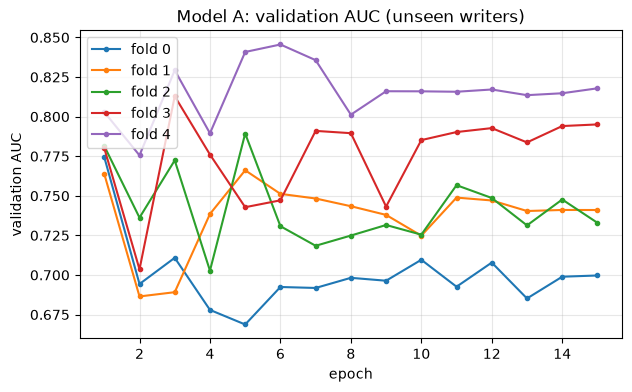

In [5]:
plt.figure(figsize=(7, 4))
for fold in FOLDS:
    h = pd.read_csv(os.path.join(RUNS, f"{MODE}_fold{fold}", "history.csv"))
    plt.plot(h.epoch, h.val_auc, marker=".", label=f"fold {fold}")
plt.xlabel("epoch"); plt.ylabel("validation AUC"); plt.title("Model A: validation AUC (unseen writers)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()